# CIS 5450 — KKBox churn: preprocessing and exploratory analysis

**Research question:** how do listening, payment, and subscription behaviors relate to the supplied churn label?

This notebook contains the entire preprocessing and EDA implementation. It does not import our Python scripts,
clone a repository, train models, or evaluate the final test set. Raw CSVs become a **970,960-user, 52-column**
Parquet, followed by development-only analysis and a **24-predictor recommendation**.

## Choose an execution route

- **Existing Parquet (default):** leave `REBUILD_FROM_RAW = False`. Upload the current Parquet into
  `data/processed/` under the working directory, or change `EXISTING_PARQUET` to its location.
  Also supply the matching metadata JSON and saved `test_user_ids.csv` when available.
- **Full reproduction:** accept the [competition rules](https://www.kaggle.com/competitions/kkbox-churn-prediction-challenge/rules),
  set `REBUILD_FROM_RAW = True`, and run the notebook from the top. Missing raw files are downloaded from Kaggle.
  This flag explicitly enables the expensive raw-data cells; they do nothing in the default route.

Run cells in order. The original listening CSV contains **392 million rows (about 30.5 GB)**. Full reproduction
needs substantial local disk for raw data, compressed downloads, temporary buckets, and DuckDB spill files.
A CPU runtime is sufficient; a GPU does not accelerate these queries. Keep scratch processing on the runtime's
local disk. Colab runtime files are temporary: save completed outputs and your notebook to Drive.

**Execution disclosure:** this notebook was converted without rerunning the expensive preprocessing.
The six saved figures are imported from the previous development EDA and explicitly labeled as prior outputs.
All code-cell execution counts are cleared; rerunning cells replaces those figures with fresh results.

## 1. Install the analysis environment

These analysis-library versions match the existing project environment. Kaggle is needed only to acquire raw data.
If Colab requests a runtime restart after installation, restart and run from the top before importing the libraries.

In [ ]:
%pip install -q duckdb==2.0.0 pandas==2.2.3 matplotlib==3.10.7 kaggle

In [ ]:
import getpass
import json
import os
import shutil
import subprocess
import tempfile
import zipfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'kkbox_matplotlib'))
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

print('DuckDB:', duckdb.__version__, '| NumPy:', np.__version__, '| pandas:', pd.__version__)

DuckDB: 2.0.0 | NumPy: 2.3.4 | pandas: 2.2.3


## 2. Configure paths and the execution route

Paths are relative to the current notebook working directory, not a particular Mac account.
For Drive input, enable the optional mount and change the existing-file paths below. For example,
`Path('/content/drive/MyDrive/KKBox/kkbox_v2_asof_20170228.parquet')`.

In raw mode, existing output files are refused rather than overwritten. Switch back to existing mode to inspect
an already completed result. In existing mode, no Kaggle credentials or raw files are required.

In [ ]:
REBUILD_FROM_RAW = True  # Change to True only when ready for the expensive full reproduction.
MOUNT_GOOGLE_DRIVE = False

ROOT = Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
FINAL_PARQUET = ROOT / 'data' / 'processed' / 'kkbox_v2_asof_20170228.parquet'
EXISTING_PARQUET = FINAL_PARQUET
EXISTING_TEST_IDS = ROOT / 'reports' / 'kkbox_v2_eda' / 'test_user_ids.csv'
OUTPUT = ROOT / 'reports' / 'kkbox_notebook'
WORK_ROOT = ROOT / 'kkbox_work' / 'notebook'

CUTOFF = '2017-02-28'
VERSION = '1.0.1'
EXPECTED_USERS = 970_960
LISTENING_BUCKETS = 64
SEED = 42
MEMORY_LIMIT = '3GB'
MAX_TEMP_DIRECTORY_SIZE = '50GB'
COMPETITION = 'kkbox-churn-prediction-challenge'
RAW_FILES = {
    'labels_raw': RAW_DIR / 'train_v2.csv',
    'members_raw': RAW_DIR / 'members_v3.csv',
    'transactions_raw': RAW_DIR / 'transactions.csv',
    'logs_raw': RAW_DIR / 'user_logs.csv',
}

if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT.mkdir(parents=True, exist_ok=True)
if REBUILD_FROM_RAW and any(os.path.lexists(p) for p in
                           [FINAL_PARQUET, FINAL_PARQUET.with_suffix('.metadata.json')]):
    raise FileExistsError('Output already exists. Use the existing-Parquet route or choose a new output path.')
print('Route:', 'rebuild from raw' if REBUILD_FROM_RAW else 'existing Parquet')
print('Free local disk:', round(shutil.disk_usage(ROOT).free / 2**30, 1), 'GiB')

Route: rebuild from raw
Free local disk: 107.3 GiB


## 3. Acquire the four original source files — raw route only

| File | Role |
| --- | --- |
| `train_v2.csv` | Supplied v2 user IDs and 0/1 churn labels |
| `members_v3.csv` | Demographics and registration date |
| Original `transactions.csv` | Historical payments, plans, renewal and cancellation |
| Original `user_logs.csv` | Historical listening through February 2017 |

We do **not** use `transactions_v2.csv` or `user_logs_v2.csv` for these features. Their later activity would
violate our observation boundary. Both behavioral sources are filtered again before any feature calculation.

Sign in and accept the competition rules first. Create a token in [Kaggle settings](https://www.kaggle.com/settings/api).
Set environment variable `KAGGLE_API_TOKEN`, use an existing Kaggle credentials file, or enter the token in the
hidden prompt below. Never paste a token into a notebook cell. The acquisition cell downloads only missing
files and extracts each archive before publishing the completed CSV. It does not print credentials.

References: [official authentication instructions](https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication)
and [competition download commands](https://github.com/Kaggle/kaggle-cli/blob/main/docs/competitions.md#kaggle-competitions-download).

In [ ]:
if REBUILD_FROM_RAW:
    missing = [path for path in RAW_FILES.values() if not path.is_file()]
    if missing:
        credentials_present = (os.environ.get('KAGGLE_API_TOKEN')
                               or (os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'))
                               or (Path.home() / '.kaggle' / 'kaggle.json').exists()
                               or (Path.home() / '.kaggle' / 'access_token').exists())
        if not credentials_present:
            os.environ['KAGGLE_API_TOKEN'] = getpass.getpass('Kaggle API token (hidden): ')
        extractor = shutil.which('7zz') or shutil.which('7z')
        if extractor is None:
            subprocess.run(['apt-get', 'update', '-qq'], check=True)
            subprocess.run(['apt-get', 'install', '-y', '-qq', 'p7zip-full'], check=True)
            extractor = shutil.which('7z')
        RAW_DIR.mkdir(parents=True, exist_ok=True)
        for destination in missing:
            print('Downloading and extracting:', destination.name)
            with tempfile.TemporaryDirectory(prefix='kaggle_download_', dir=RAW_DIR) as folder:
                archive_name = destination.name + '.7z'
                subprocess.run(['kaggle', 'competitions', 'download', COMPETITION,
                                '-f', archive_name, '-p', folder], check=True)
                archive = Path(folder) / archive_name
                # Some API downloads wrap the requested archive in a ZIP.
                if not archive.exists():
                    for wrapper in Path(folder).glob('*.zip'):
                        with zipfile.ZipFile(wrapper) as z:
                            z.extractall(folder)
                archive = next(Path(folder).rglob(archive_name))
                unpacked = Path(folder) / 'unpacked'
                subprocess.run([extractor, 'x', str(archive), f'-o{unpacked}', '-y'], check=True)
                extracted = next(unpacked.rglob(destination.name))
                destination.parent.mkdir(parents=True, exist_ok=True)
                os.link(extracted, destination)  # Refuse replacement of an existing CSV.
        print('All required raw files are available.')
    else:
        print('Using existing raw CSVs; no download needed.')
else:
    print('Raw download skipped.')

Kaggle API token (hidden): ··········
All required raw files are available.


## 4. Start a fresh DuckDB work database — raw route only

DuckDB reads CSV columns as text so that conversions are explicit. `TRY_CAST` and `TRY_STRPTIME`
turn unparseable fields into NULL. A view names a query; a table stores its results.
We snapshot labels once, use one thread, and put database/spill files in fresh local scratch storage.
The 50 GB spill cap excludes raw files, the work database, and temporary Parquet buckets.

In [ ]:
def sql_string(value):
    return "'" + str(value).replace("'", "''") + "'"

def source_identity(paths):
    return {name: {"path": str(path), "bytes": path.stat().st_size,
                   "mtime_ns": path.stat().st_mtime_ns} for name, path in paths.items()}

In [ ]:
if REBUILD_FROM_RAW:

    WORK_ROOT.mkdir(parents=True, exist_ok=True)
    work_session = tempfile.TemporaryDirectory(prefix='kkbox_asof_', dir=WORK_ROOT)
    work = Path(work_session.name)
    con = duckdb.connect(str(work / 'work.duckdb'))
    con.execute(f'SET memory_limit = {sql_string(MEMORY_LIMIT)}')
    con.execute('SET threads = 1')
    con.execute('SET preserve_insertion_order = false')
    con.execute(f"SET temp_directory = {sql_string(work / 'spill')}")
    con.execute(f'SET max_temp_directory_size = {sql_string(MAX_TEMP_DIRECTORY_SIZE)}')
    paths = {name: path.resolve() for name, path in RAW_FILES.items()}
    before = source_identity(paths)
    for name, path in paths.items():
        con.execute(f"CREATE VIEW {name} AS SELECT * FROM read_csv({sql_string(path)}, header=true, all_varchar=true, ignore_errors=false)")
    con.execute('CREATE TABLE label_snapshot AS SELECT * FROM labels_raw')
    con.execute('CREATE OR REPLACE VIEW labels_raw AS SELECT * FROM label_snapshot')

### 4.1 Validate the unchanged labels

Require exactly 970,960 rows and distinct users, valid IDs, and labels equal to 0 or 1.
`train` is the population to preserve throughout the joins. We never use the target to calculate behavioral features.

In [ ]:
if REBUILD_FROM_RAW:
    rows, users, invalid = con.execute("""
        SELECT COUNT(*), COUNT(DISTINCT msno),
               COUNT(*) FILTER (WHERE msno IS NULL OR TRIM(msno) = ''
                   OR is_churn IS NULL OR is_churn NOT IN ('0', '1'))
        FROM labels_raw
    """).fetchone()

    if (rows, users, invalid) != (EXPECTED_USERS, EXPECTED_USERS, 0):
        raise ValueError(f"Invalid labels: rows={rows}, users={users}, invalid={invalid}")

    con.execute("""
        CREATE TABLE train AS
        SELECT msno, CAST(is_churn AS INTEGER) AS is_churn FROM labels_raw
    """)

### 4.2 Clean demographics

Convert registration dates and ages; trim blank categories to NULL. Ages outside 1–100 become NULL.
If registration is missing, unparseable, or after February 28, mask the demographic fields but retain the labeled
user. Duplicate member records for labeled users cause an error. `has_demographics` indicates a usable
registration record, not that every demographic field is present.

In [ ]:
if REBUILD_FROM_RAW:
    con.execute(f"""
        CREATE TABLE member_features AS
        WITH parsed AS (
            SELECT m.*, TRY_STRPTIME(registration_init_time, '%Y%m%d')::DATE AS reg
            FROM members_raw m INNER JOIN train t USING (msno)
        ), usable AS (
            SELECT *, reg <= DATE '{CUTOFF}' AS available FROM parsed
        )
        SELECT msno,
               CAST(COALESCE(available, FALSE) AS INTEGER) AS has_demographics,
               CASE WHEN available THEN NULLIF(TRIM(city), '') END AS city,
               CASE WHEN available AND TRY_CAST(bd AS INTEGER) BETWEEN 1 AND 100
                    THEN TRY_CAST(bd AS INTEGER) END AS age,
               CASE WHEN available THEN NULLIF(TRIM(gender), '') END AS gender,
               CASE WHEN available THEN NULLIF(TRIM(registered_via), '') END AS registered_via,
               CASE WHEN available THEN reg END AS registration_date,
               reg > DATE '{CUTOFF}' AS registration_after_cutoff
        FROM usable
    """)

    duplicates = con.execute("""
        SELECT COUNT(*) FROM (
            SELECT msno FROM member_features GROUP BY msno HAVING COUNT(*) > 1
        )
    """).fetchone()[0]

    if duplicates:
        raise ValueError(f"Conflicting/duplicate member records for {duplicates} training users")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 5. Filter and clean transactions

The INNER JOIN restricts records to labeled users, and the date predicate excludes future/unparseable
transaction dates **before** aggregation or ordering. Invalid/negative amounts and plan lengths become NULL;
zero is valid. Only literal 0/1 flags are accepted. A record with a valid eligible date remains a transaction
count even if another field is invalid. Counts represent event rows, not successful purchases.

In [ ]:
if REBUILD_FROM_RAW:
    con.execute(f"""
        CREATE TABLE transaction_events AS
        WITH eligible AS (
            SELECT x.*, TRY_STRPTIME(transaction_date, '%Y%m%d')::DATE AS txn_date
            FROM transactions_raw x INNER JOIN train t USING (msno)
            WHERE TRY_STRPTIME(transaction_date, '%Y%m%d')::DATE <= DATE '{CUTOFF}'
        ), parsed AS (
            SELECT msno, txn_date,
                   TRY_STRPTIME(membership_expire_date, '%Y%m%d')::DATE AS expire_date,
                   TRY_CAST(actual_amount_paid AS DOUBLE) AS paid,
                   TRY_CAST(payment_plan_days AS INTEGER) AS plan_days,
                   CASE WHEN is_cancel IN ('0', '1')
                        THEN CAST(is_cancel AS INTEGER) END AS cancel,
                   CASE WHEN is_auto_renew IN ('0', '1')
                        THEN CAST(is_auto_renew AS INTEGER) END AS renew,
                   CASE WHEN plan_list_price IS NOT NULL AND payment_plan_days IS NOT NULL
                                  AND payment_method_id IS NOT NULL
                        THEN CONCAT(plan_list_price, payment_plan_days, payment_method_id)
                   END AS plan_sort
            FROM eligible
        )
        SELECT msno, txn_date, expire_date, plan_sort,
               CASE WHEN paid >= 0 AND ISFINITE(paid) THEN paid END AS paid,
               CASE WHEN plan_days >= 0 THEN plan_days END AS plan_days,
               cancel, renew
        FROM parsed
    """)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

### 5.1 Aggregate transaction history to one row per user

`GROUP BY msno` calculates counts, payment/plan statistics, renewal rates, and cancellation history.
`ROW_NUMBER()` chooses the latest recorded state. For same-day records, the organizer convention chooses the
smallest lexicographic price/duration/payment-method signature; cancellation follows subscription;
within cancellations earliest expiry wins, within renewals latest expiry wins. Extra payment/renewal/duration
keys resolve remaining ties deterministically. This is a convention, not an observed intraday timestamp.

Every recency uses February 28, never the source maximum date. A cancellation is not automatically churn.
Transactions after the last cancellation must have a **strictly later date**; no known cancellation gives NULL.

In [ ]:
if REBUILD_FROM_RAW:
    con.execute(f"""
        CREATE TABLE transaction_features AS
        WITH ordered AS (
            SELECT *,
                   MAX(txn_date) FILTER (WHERE cancel = 1)
                       OVER (PARTITION BY msno) AS last_cancel_date,
                   ROW_NUMBER() OVER (
                       PARTITION BY msno ORDER BY txn_date DESC,
                           plan_sort ASC NULLS LAST, cancel DESC NULLS LAST,
                           CASE WHEN cancel = 1 THEN expire_date END ASC NULLS LAST,
                           CASE WHEN cancel = 0 THEN expire_date END DESC NULLS LAST,
                           paid DESC NULLS LAST, renew DESC NULLS LAST,
                           plan_days DESC NULLS LAST, expire_date DESC NULLS LAST
                   ) AS rn
            FROM transaction_events
        )
        SELECT msno, COUNT(*) AS transaction_count,
               COUNT(*) FILTER (WHERE txn_date > DATE '{CUTOFF}' - INTERVAL 30 DAY)
                   AS transaction_count_30d,
               COUNT(*) FILTER (WHERE txn_date > DATE '{CUTOFF}' - INTERVAL 90 DAY)
                   AS transaction_count_90d,
               COUNT(*) FILTER (WHERE paid IS NULL OR plan_days IS NULL
                   OR cancel IS NULL OR renew IS NULL OR expire_date IS NULL)
                   AS invalid_transaction_rows,
               MAX(txn_date) AS last_transaction_date,
               DATE_DIFF('day', MAX(txn_date), DATE '{CUTOFF}') AS days_since_last_transaction,
               SUM(paid) AS total_amount_paid, AVG(paid) AS avg_amount_paid,
               MAX(paid) FILTER (WHERE rn = 1) AS last_amount_paid,
               AVG(plan_days) AS avg_plan_days,
               MAX(plan_days) FILTER (WHERE rn = 1) AS last_plan_days,
               MAX(expire_date) FILTER (WHERE rn = 1) AS last_membership_expire_date,
               AVG(renew) AS auto_renew_rate,
               MAX(renew) FILTER (WHERE rn = 1) AS last_is_auto_renew,
               MAX(cancel) AS ever_cancel,
               COUNT(*) FILTER (WHERE cancel = 1) AS cancel_count,
               AVG(cancel) AS cancel_ratio,
               MAX(cancel) FILTER (WHERE rn = 1) AS last_is_cancel,
               DATE_DIFF('day', MAX(last_cancel_date), DATE '{CUTOFF}') AS days_since_last_cancel,
               COUNT(*) FILTER (WHERE cancel = 1
                   AND txn_date > DATE '{CUTOFF}' - INTERVAL 30 DAY) AS cancel_count_30d,
               COUNT(*) FILTER (WHERE cancel = 1
                   AND txn_date > DATE '{CUTOFF}' - INTERVAL 90 DAY) AS cancel_count_90d,
               CASE WHEN MAX(last_cancel_date) IS NOT NULL
                    THEN COUNT(*) FILTER (WHERE txn_date > last_cancel_date)
               END AS transactions_since_last_cancel
        FROM ordered GROUP BY msno
    """)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 6. Filter listening history and create 64 bounded working groups

Reading 392 million rows into pandas would consume too much RAM. One DuckDB CSV scan keeps only labeled users
and dates at/before cutoff, cleans six fields, then writes compressed Parquet buckets using `HASH(msno) % 64`.
All records for a user stay together. Later exact distinct-date counting therefore needs to handle only one
bucket at a time. Eight open writer files and small row groups limit writer buffering. Buckets are temporary,
not a cache. Negative/unparseable measurements become NULL; genuine zeros are preserved. A row's five-bucket
song total is NULL if any component is invalid; nonfinite seconds also become NULL.

In [ ]:
if REBUILD_FROM_RAW:
    con.execute("SET partitioned_write_max_open_files = 8")
    listening_session = tempfile.TemporaryDirectory(prefix='listening_', dir=work)
    staging = listening_session.name
    con.execute(f"""
    COPY (
    WITH eligible AS NOT MATERIALIZED (
        SELECT l.msno, TRY_STRPTIME(date, '%Y%m%d')::DATE AS activity_date,
               l.num_25, l.num_50, l.num_75, l.num_985,
               l.num_100, l.num_unq, l.total_secs
        FROM logs_raw l INNER JOIN train t USING (msno)
        WHERE TRY_STRPTIME(date, '%Y%m%d')::DATE <= DATE '{CUTOFF}'
    ), parsed AS NOT MATERIALIZED (
        SELECT msno, activity_date,
               TRY_CAST(num_25 AS BIGINT) AS n25,
               TRY_CAST(num_50 AS BIGINT) AS n50,
               TRY_CAST(num_75 AS BIGINT) AS n75,
               TRY_CAST(num_985 AS BIGINT) AS n985,
               TRY_CAST(num_100 AS BIGINT) AS n100,
               TRY_CAST(num_unq AS BIGINT) AS unq,
               TRY_CAST(total_secs AS DOUBLE) AS secs
        FROM eligible
    ), cleaned AS NOT MATERIALIZED (
        SELECT msno, activity_date,
               CASE WHEN n25 >= 0 AND n50 >= 0 AND n75 >= 0
                              AND n985 >= 0 AND n100 >= 0
                    THEN n25::HUGEINT + n50 + n75 + n985 + n100 END AS songs,
               CASE WHEN n100 >= 0 THEN n100 END AS songs_100,
               CASE WHEN unq >= 0 THEN unq END AS unique_songs,
               CASE WHEN secs >= 0 AND ISFINITE(secs) THEN secs END AS seconds
        FROM parsed
    )
    SELECT *, CAST(HASH(msno) % {LISTENING_BUCKETS} AS INTEGER) AS bucket
    FROM cleaned
    ) TO {sql_string(staging)}
    (FORMAT PARQUET, COMPRESSION ZSTD, PARTITION_BY (bucket), ROW_GROUP_SIZE 16384)
    """)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

### 6.1 Calculate listening activity and recent windows

Each bucket is grouped by user. Multiple records on one date contribute measurements but count as one
recorded active day. A recorded day is not necessarily a positive-activity day. SQL sums ignore NULLs, so
mixed-validity histories give partial observed totals; quality counts preserve that warning.

| Window | Inclusive dates |
| --- | --- |
| Last 7 days | February 22–28, 2017 |
| Last 30 days | January 30–February 28, 2017 |
| Previous 30 days | December 31, 2016–January 29, 2017 |
| Last 90 days (transactions) | December 1, 2016–February 28, 2017 |

With history but no recent records, window counts/sums are zero. With recent rows whose measurements are all
invalid, their sum stays NULL. With no historical match, the later LEFT JOIN leaves measurements NULL and
sets the history indicator to 0. Summed daily unique songs are not lifetime distinct tracks.

In [ ]:
if REBUILD_FROM_RAW:
    con.execute("""
        CREATE TABLE listening_features (
            msno VARCHAR, listening_record_count BIGINT, invalid_listening_rows BIGINT,
            active_days BIGINT, total_songs HUGEINT, total_songs_100 HUGEINT,
            total_unique_songs_daily HUGEINT, total_listening_secs DOUBLE,
            avg_secs_per_active_day DOUBLE, last_active_date DATE,
            days_since_last_active BIGINT, active_days_7d BIGINT, active_days_30d BIGINT,
            listening_secs_7d DOUBLE, listening_secs_30d DOUBLE,
            listening_secs_previous_30d DOUBLE, songs_30d HUGEINT
        )
    """)

    for bucket in range(LISTENING_BUCKETS):
        folder = Path(staging) / f"bucket={bucket}"
        if not folder.exists():
            continue
        print(f"Aggregating listening bucket {bucket + 1}/{LISTENING_BUCKETS}...", flush=True)
        con.execute(f"""
    INSERT INTO listening_features
    SELECT msno, COUNT(*) AS listening_record_count,
           COUNT(*) FILTER (WHERE seconds IS NULL OR songs IS NULL
                               OR unique_songs IS NULL) AS invalid_listening_rows,
           COUNT(DISTINCT activity_date) AS active_days,
           SUM(songs) AS total_songs,
           SUM(songs_100) AS total_songs_100,
           SUM(unique_songs) AS total_unique_songs_daily,
           SUM(seconds) AS total_listening_secs,
           SUM(seconds) / COUNT(DISTINCT activity_date) AS avg_secs_per_active_day,
           MAX(activity_date) AS last_active_date,
           DATE_DIFF('day', MAX(activity_date), DATE '{CUTOFF}') AS days_since_last_active,
           COUNT(DISTINCT activity_date) FILTER (
               WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 7 DAY) AS active_days_7d,
           COUNT(DISTINCT activity_date) FILTER (
               WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 30 DAY) AS active_days_30d,
           CASE WHEN COUNT(*) FILTER (
               WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 7 DAY) = 0 THEN 0
               ELSE SUM(seconds) FILTER (
                   WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 7 DAY)
           END AS listening_secs_7d,
           CASE WHEN COUNT(*) FILTER (
               WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 30 DAY) = 0 THEN 0
               ELSE SUM(seconds) FILTER (
                   WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 30 DAY)
           END AS listening_secs_30d,
           CASE WHEN COUNT(*) FILTER (
               WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 60 DAY
                 AND activity_date <= DATE '{CUTOFF}' - INTERVAL 30 DAY) = 0 THEN 0
               ELSE SUM(seconds) FILTER (
                   WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 60 DAY
                     AND activity_date <= DATE '{CUTOFF}' - INTERVAL 30 DAY)
           END AS listening_secs_previous_30d,
           CASE WHEN COUNT(*) FILTER (
               WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 30 DAY) = 0 THEN 0
               ELSE SUM(songs) FILTER (
                   WHERE activity_date > DATE '{CUTOFF}' - INTERVAL 30 DAY)
           END AS songs_30d
    FROM read_parquet({sql_string(folder / '*.parquet')}, hive_partitioning=false)
    GROUP BY msno
        """)
        # This run owns these files; release disk space after their aggregation succeeds.
        for parquet in folder.glob("*.parquet"):
            parquet.unlink()
        folder.rmdir()
    listening_session.cleanup()

Aggregating listening bucket 1/64...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Aggregating listening bucket 2/64...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Aggregating listening bucket 3/64...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (118 outputs left out)

Aggregating listening bucket 63/64...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Aggregating listening bucket 64/64...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 7. LEFT JOIN onto labels and validate

Every feature table has one row per user **before** joining. LEFT JOIN preserves labeled users without matching
records and avoids multiplying transaction rows by listening rows. The join also derives the absolute and
relative 30-day listening changes; division by zero becomes NULL.

Require unique feature keys, no contributing post-cutoff behavior, exactly 970,960 output rows and users,
and identical user/label pairs. Metadata reports matched-history counts and masked future registrations.

In [ ]:
if REBUILD_FROM_RAW:
    for table in ("member_features", "listening_features", "transaction_features"):
        rows, users = con.execute(f"SELECT COUNT(*), COUNT(DISTINCT msno) FROM {table}").fetchone()
        if rows != users:
            raise ValueError(f"Duplicate IDs in {table}")

    for table, column in (("transaction_events", "txn_date"),
                          ("listening_features", "last_active_date")):
        future = con.execute(f"SELECT COUNT(*) FROM {table} WHERE {column} > DATE '{CUTOFF}'").fetchone()[0]
        if future:
            raise ValueError(f"Future events in {table}")

    con.execute("""
        CREATE TABLE final AS
        SELECT t.*, m.* EXCLUDE (msno, registration_after_cutoff, has_demographics),
               COALESCE(m.has_demographics, 0) AS has_demographics,
               CAST(m.age IS NULL AS INTEGER) AS age_missing,
               CAST(m.gender IS NULL AS INTEGER) AS gender_missing,
               CAST(l.msno IS NOT NULL AS INTEGER) AS has_listening_logs,
               l.* EXCLUDE (msno),
               l.listening_secs_30d - l.listening_secs_previous_30d AS listening_secs_change_30d,
               l.listening_secs_30d / NULLIF(l.listening_secs_previous_30d, 0)
                   AS listening_secs_ratio_30d,
               CAST(x.msno IS NOT NULL AS INTEGER) AS has_transactions,
               x.* EXCLUDE (msno)
        FROM train t
        LEFT JOIN member_features m USING (msno)
        LEFT JOIN listening_features l USING (msno)
        LEFT JOIN transaction_features x USING (msno)
    """)

    rows, users = con.execute("SELECT COUNT(*), COUNT(DISTINCT msno) FROM final").fetchone()

    changed = con.execute("""
        SELECT COUNT(*) FROM final f LEFT JOIN train t USING (msno)
        WHERE t.msno IS NULL OR f.is_churn IS DISTINCT FROM t.is_churn
    """).fetchone()[0]

    if (rows, users, changed) != (EXPECTED_USERS, EXPECTED_USERS, 0):
        raise ValueError(f"Final validation failed: rows={rows}, users={users}, changed={changed}")
    summary = dict(zip(("rows", "unique_users", "users_with_transactions", "users_with_logs"),
                    con.execute("""SELECT COUNT(*), COUNT(DISTINCT msno),
                        SUM(has_transactions), SUM(has_listening_logs) FROM final""").fetchone()))
    display(pd.DataFrame([summary]))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,rows,unique_users,users_with_transactions,users_with_logs
0,970960,970960,968433,850296


### 7.1 Publish the final Parquet and provenance without overwriting

Check that source identities did not change during processing. Save a compressed 52-column Parquet and
metadata JSON with paths, sizes, modification times, cutoff, versions, and validation results. Staged files
are published using no-overwrite hard links; work storage is cleaned after successful completion. Source
identities are not cryptographic checksums. Existing Parquet and code files are never rewritten by this cell.

In [ ]:
if REBUILD_FROM_RAW:

    summary['masked_future_registrations'] = con.execute(
        'SELECT COUNT(*) FROM member_features WHERE registration_after_cutoff').fetchall()[0][0]
    if source_identity(paths) != before:
        raise RuntimeError('A raw source changed during processing; output was not published.')
    provenance = {
        'preprocessing_version': VERSION, 'notebook_version': '1.0',
        'duckdb_version': duckdb.__version__, 'numpy_version': np.__version__,
        'pandas_version': pd.__version__, 'cutoff_inclusive': CUTOFF,
        'sources': before, 'validation': summary,
        'resources': {'memory_limit': MEMORY_LIMIT, 'threads': 1,
                      'max_temp_directory_size': MAX_TEMP_DIRECTORY_SIZE,
                      'listening_buckets': LISTENING_BUCKETS},
    }
    FINAL_PARQUET.parent.mkdir(parents=True, exist_ok=True)
    metadata_path = FINAL_PARQUET.with_suffix('.metadata.json')
    with tempfile.TemporaryDirectory(prefix='.kkbox_publish_', dir=FINAL_PARQUET.parent) as folder:
        parquet = Path(folder) / 'data.parquet'
        manifest = Path(folder) / 'metadata.json'
        con.execute(f'COPY final TO {sql_string(parquet)} (FORMAT PARQUET, COMPRESSION ZSTD)')
        manifest.write_text(json.dumps(provenance, indent=2))
        os.link(manifest, metadata_path)
        try:
            os.link(parquet, FINAL_PARQUET)
        except BaseException:
            metadata_path.unlink()
            raise
    con.close()
    work_session.cleanup()
    print('Saved:', FINAL_PARQUET)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved: /content/data/processed/kkbox_v2_asof_20170228.parquet


In [ ]:
import duckdb

duckdb.sql("""
    COPY (
        SELECT *
        FROM 'data/processed/kkbox_v2_asof_20170228.parquet'
    )
    TO 'data/processed/kkbox_v2_excel.csv'
    (HEADER, DELIMITER ',');
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CountBIGINT
970960


## 8. Load the result for development-only EDA — both routes

Existing mode reads only the selected Parquet, optional metadata, and optional saved test IDs. Upload these
files using Colab's Files panel or mount Drive in the configuration cell. If the file is on Drive, we copy it
to a temporary local directory for faster repeated scans, without changing the Drive original.
Check 970,960 unique users and the expected 52-column schema. No raw CSV is read in the existing route.
A missing metadata sidecar is reported explicitly: the notebook can still analyze the Parquet, but cannot
claim independently verified provenance from that file alone.

In [ ]:
SOURCE = FINAL_PARQUET if REBUILD_FROM_RAW else EXISTING_PARQUET
if not SOURCE.is_file():
    raise FileNotFoundError(f'Upload your Parquet or update EXISTING_PARQUET: {SOURCE}')
original_source = SOURCE
original_stat = (SOURCE.stat().st_size, SOURCE.stat().st_mtime_ns)
metadata_path = SOURCE.with_suffix('.metadata.json')
metadata = json.loads(metadata_path.read_text()) if metadata_path.is_file() else None
if metadata is not None and metadata.get('cutoff_inclusive') != CUTOFF:
    raise ValueError('The metadata cutoff differs from this notebook configuration.')
print('Metadata:', 'available' if metadata is not None else 'not supplied; provenance not verified')
local_input = None
if str(SOURCE).startswith('/content/drive/'):
    local_input = tempfile.TemporaryDirectory(prefix='kkbox_input_')
    SOURCE = Path(local_input.name) / original_source.name
    shutil.copy2(original_source, SOURCE)

con = duckdb.connect()
con.execute("SET memory_limit='1GB'")
con.execute('SET threads=1')
con.read_parquet(str(SOURCE)).create_view('source')
schema = con.execute('DESCRIBE source').df()
rows, users = con.execute('SELECT COUNT(*), COUNT(DISTINCT msno) FROM source').fetchall()[0]
if (rows, users, len(schema)) != (EXPECTED_USERS, EXPECTED_USERS, 52):
    raise ValueError(f'Unexpected dataset: {rows} rows, {users} users, {len(schema)} columns')
display(schema)

Metadata: available


,column_name,column_type,null,key,default,extra
0,msno,VARCHAR,YES,None,None,None
1,is_churn,INTEGER,YES,None,None,None
2,city,VARCHAR,YES,None,None,None
3,age,INTEGER,YES,None,None,None
4,gender,VARCHAR,YES,None,None,None
5,registered_via,VARCHAR,YES,None,None,None
6,registration_date,DATE,YES,None,None,None
7,has_demographics,INTEGER,YES,None,None,None
8,age_missing,INTEGER,YES,None,None,None
9,gender_missing,INTEGER,YES,None,None,None


## 9. Freeze the stratified 80/20 development/test split

Only IDs and labels are used to establish this boundary. Sort IDs, independently permute each class with
NumPy seed 42, and hold out 20% of each. This exactly preserves our existing split algorithm: **776,768
development** and **194,192 test** users on the current dataset. If saved IDs are supplied, verify equality;
never silently change them. All subsequent feature statistics, plots and selection use development rows only.
This is a within-cohort holdout, not a future-month deployment evaluation.

In [ ]:
# Read only IDs/labels to establish the boundary; never inspect test feature values.
labels = con.execute("SELECT msno, is_churn FROM source ORDER BY msno").df()
if not labels.is_churn.isin([0, 1]).all():
    raise ValueError("Invalid churn labels")
rng = np.random.default_rng(SEED)
test_indices = np.concatenate([
    rng.permutation(labels.index[labels.is_churn == label])[:round(.2 * (labels.is_churn == label).sum())]
    for label in (0, 1)
])
test_ids = labels.loc[test_indices, ["msno"]].sort_values("msno").reset_index(drop=True)
saved_test_path = EXISTING_TEST_IDS
if saved_test_path.is_file() and not pd.read_csv(saved_test_path).equals(test_ids):
    raise ValueError('Supplied saved test IDs differ from the original seeded split.')
test_path = OUTPUT / "test_user_ids.csv"
if test_path.exists():
    if not pd.read_csv(test_path).equals(test_ids):
        raise ValueError("Existing test IDs differ; refusing to change the evaluation split")
else:
    test_ids.to_csv(test_path, index=False)
dev_ids = labels.drop(index=test_indices)[["msno"]]
con.register("dev_ids", dev_ids)
con.execute("""CREATE VIEW dev AS
    SELECT s.*,
           DATE_DIFF('day', registration_date, DATE '2017-02-28') AS membership_tenure_days,
           CASE WHEN invalid_listening_rows = 0 AND total_songs > 0
                      AND total_songs_100 BETWEEN 0 AND total_songs
                THEN total_songs_100 / total_songs END AS song_completion_rate,
           CASE WHEN last_membership_expire_date <> DATE '1970-01-01'
                THEN DATE_DIFF('day', DATE '2017-02-28', last_membership_expire_date)
           END AS days_until_expiration
    FROM source s INNER JOIN dev_ids USING (msno)
""")
del labels, test_indices
print(f"Development: {len(dev_ids):,}; test: {len(test_ids):,}. Test rows excluded from feature analysis.", flush=True)

Development: 776,768; test: 194,192. Test rows excluded from feature analysis.


### Derived features and missing-value rules

The development view above adds three columns without changing the Parquet:

- **Membership tenure:** cutoff minus usable registration date; missing registration gives NULL.
- **Song completion rate:** `total_songs_100 / total_songs`. The numerator counts plays over 98.5% completion.
  Zero/missing denominator, inconsistent counts, or any flagged invalid listening history gives NULL.
- **Days until expiration:** recorded expiry minus cutoff. Negative values mean already expired. The likely
  `1970-01-01` placeholder becomes NULL; this masking rule is an explicit assumption.

Expiration after cutoff is permitted when recorded in a past eligible transaction; post-cutoff transactions
are never consulted. The values are not imputed, clipped, standardized, or otherwise fitted to a model.

## 10. Basic quality checks and descriptive statistics

Use development rows only. Missing percentages distinguish absent history from zero activity. Means/min/max
and approximate median/P99 expose skew and extreme values. Additional checks report invalid ages, binary
flags/rates, date/recency inconsistencies, window constraints, invalid-row counts, and likely placeholders.
Findings are diagnostics: no users are dropped and no automatic outlier clipping is applied.

In [ ]:
numeric = schema.loc[schema.column_type.isin(["INTEGER", "BIGINT", "DOUBLE", "HUGEINT"]), "column_name"].tolist()
numeric = [c for c in numeric if c != "is_churn"]
derived = ["membership_tenure_days", "song_completion_rate", "days_until_expiration"]
quality = []
for column in schema.column_name.tolist() + derived:
    dtype = schema.set_index("column_name").column_type.get(column, "derived")
    if column in numeric + derived:
        result = con.execute(f'''SELECT COUNT(*) - COUNT("{column}"),
            MIN("{column}"), AVG("{column}"),
            APPROX_QUANTILE("{column}", [0.5, 0.99]), MAX("{column}"),
            COUNT(*) FILTER (WHERE "{column}" IS NOT NULL AND NOT ISFINITE("{column}"))
            FROM dev''').fetchall()[0]
        missing, low, mean, quantiles, high, nonfinite = result
        median, p99 = quantiles if quantiles else [None, None]
    elif dtype == "DATE":
        missing, low, high = con.execute(f'''SELECT COUNT(*) - COUNT("{column}"),
            MIN("{column}"), MAX("{column}") FROM dev''').fetchall()[0]
        mean = median = p99 = None
        nonfinite = 0
    else:
        missing = con.execute(f'SELECT COUNT(*) - COUNT("{column}") FROM dev').fetchall()[0][0]
        low = mean = median = p99 = high = None
        nonfinite = 0
    quality.append([column, dtype, missing / len(dev_ids) * 100, low, mean, median, p99, high, nonfinite])
quality = pd.DataFrame(quality, columns=["Column", "Type", "Missing %", "Min", "Mean", "Median", "P99", "Max", "Nonfinite"])


display(quality)

,Column,Type,Missing %,Min,Mean,Median,P99,Max,Nonfinite
0,msno,VARCHAR,0.000000,None,NaN,NaN,NaN,None,0
1,is_churn,INTEGER,0.000000,None,NaN,NaN,NaN,None,0
2,city,VARCHAR,11.429796,None,NaN,NaN,NaN,None,0
3,age,INTEGER,60.274110,1,2.991390e+01,2.800000e+01,5.700000e+01,100,0
4,gender,VARCHAR,60.012256,None,NaN,NaN,NaN,None,0
5,registered_via,VARCHAR,11.429796,None,NaN,NaN,NaN,None,0
6,registration_date,DATE,11.429796,2004-03-26,NaN,NaN,NaN,2017-02-28,0
7,has_demographics,INTEGER,0.000000,0,8.857020e-01,1.000000e+00,1.000000e+00,1,0
8,age_missing,INTEGER,0.000000,0,6.027411e-01,1.000000e+00,1.000000e+00,1,0
9,gender_missing,INTEGER,0.000000,0,6.001226e-01,1.000000e+00,1.000000e+00,1,0


In [ ]:
nonnegative = [c for c in numeric if c not in ["listening_secs_change_30d", "listening_secs_ratio_30d"]]
checks = {
    "Negative nonnegative-valued fields (row count, possibly overlapping)": " OR ".join(f'"{c}" < 0' for c in nonnegative),
    "Age outside 1–100": "age NOT BETWEEN 1 AND 100",
    "Rate outside 0–1": "auto_renew_rate NOT BETWEEN 0 AND 1 OR cancel_ratio NOT BETWEEN 0 AND 1 OR song_completion_rate NOT BETWEEN 0 AND 1",
    "Post-cutoff recorded behavior/registration": "last_active_date > DATE '2017-02-28' OR last_transaction_date > DATE '2017-02-28' OR registration_date > DATE '2017-02-28'",
    "Listening recency disagrees with date": "days_since_last_active <> DATE_DIFF('day', last_active_date, DATE '2017-02-28')",
    "Transaction recency disagrees with date": "days_since_last_transaction <> DATE_DIFF('day', last_transaction_date, DATE '2017-02-28')",
    "Inconsistent listening windows": "active_days_7d > 7 OR active_days_30d > 30 OR active_days_7d > active_days_30d OR active_days_30d > active_days OR active_days > listening_record_count",
    "Inconsistent transaction windows": "transaction_count_30d > transaction_count_90d OR transaction_count_90d > transaction_count OR cancel_count_30d > cancel_count_90d OR cancel_count_90d > cancel_count",
    "No-log indicator with nonmissing measurements": "has_listening_logs=0 AND (active_days IS NOT NULL OR total_listening_secs IS NOT NULL)",
    "No-transaction indicator with nonmissing count": "has_transactions=0 AND transaction_count IS NOT NULL",
    "Masked demographics with nonmissing attributes": "has_demographics=0 AND (registration_date IS NOT NULL OR city IS NOT NULL OR age IS NOT NULL OR gender IS NOT NULL OR registered_via IS NOT NULL)",
    "Users with invalid listening rows": "invalid_listening_rows > 0",
    "Users with invalid transaction rows": "invalid_transaction_rows > 0",
    "Raw completion ratio unavailable/unsafe despite logs": "has_listening_logs=1 AND song_completion_rate IS NULL",
    "Historical average listening above 24 hours per recorded day": "avg_secs_per_active_day > 86400",
    "Recent listening above 24 hours per recorded day": "listening_secs_30d > active_days_30d * 86400",
    "Likely epoch-date expiration sentinel (masked in derived feature)": "last_membership_expire_date = DATE '1970-01-01'",
}
checks.update({f"Invalid binary {c}": f"{c} NOT IN (0,1)" for c in
               ["has_demographics", "has_listening_logs", "has_transactions", "age_missing", "gender_missing", "last_is_auto_renew", "last_is_cancel", "ever_cancel"]})
checks_frame = pd.DataFrame([(name, con.execute(f"SELECT COUNT(*) FROM dev WHERE {condition}").fetchall()[0][0])
                             for name, condition in checks.items()], columns=["Check", "Development users"])


display(checks_frame)

,Check,Development users
0,"Negative nonnegative-valued fields (row count,...",0
1,Age outside 1–100,0
2,Rate outside 0–1,0
3,Post-cutoff recorded behavior/registration,0
4,Listening recency disagrees with date,0
5,Transaction recency disagrees with date,0
6,Inconsistent listening windows,0
7,Inconsistent transaction windows,0
8,No-log indicator with nonmissing measurements,0
9,No-transaction indicator with nonmissing count,0


## 11. Compare customer groups

Averages of 0/1 churn labels are churn proportions. Medians omit missing measurements and are less sensitive
to extreme values than means; status percentages use nonmissing flags. These are descriptive comparisons,
not causal effects or statistical proof of incremental predictive value.

In [ ]:
balance = con.execute("SELECT is_churn, COUNT(*) AS users FROM dev GROUP BY 1 ORDER BY 1").df()
medians = con.execute("""SELECT is_churn, COUNT(*) AS users,
    MEDIAN(days_since_last_active) AS listening_recency,
    MEDIAN(active_days_30d) AS active_days_30d,
    MEDIAN(listening_secs_30d)/3600 AS listening_hours_30d,
    MEDIAN(transaction_count) AS transactions,
    MEDIAN(last_amount_paid) AS last_payment,
    AVG(last_is_auto_renew)*100 AS latest_auto_renew_pct,
    AVG(last_is_cancel)*100 AS latest_cancel_pct,
    MEDIAN(days_until_expiration) AS days_until_expiration
    FROM dev GROUP BY 1 ORDER BY 1""").df()


display(balance, medians)

,is_churn,users
0,0,706904
1,1,69864


,is_churn,users,listening_recency,active_days_30d,listening_hours_30d,transactions,last_payment,latest_auto_renew_pct,latest_cancel_pct,days_until_expiration
0,0,706904,0.0,15.0,17.801679,17.0,149.0,92.398153,0.531758,17.0
1,1,69864,0.0,15.0,18.461814,9.0,149.0,44.747823,9.575319,14.0


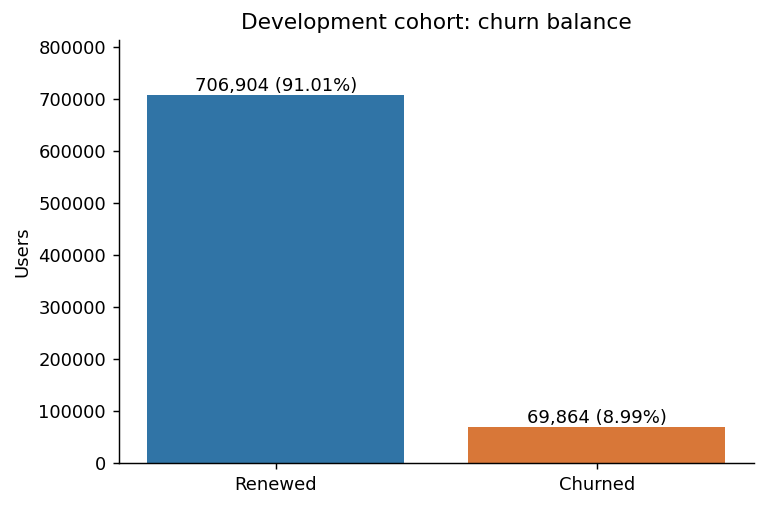

In [ ]:
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
groups = []
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(["Renewed", "Churned"], balance.users, color=["#3074a6", "#d87738"])
for i, n in enumerate(balance.users):
    ax.text(i, n, f"{n:,} ({100*n/len(dev_ids):.2f}%)", ha="center", va="bottom")
ax.set(title="Development cohort: churn balance", ylabel="Users", ylim=(0, max(balance.users)*1.15))
fig.tight_layout(); fig.savefig(OUTPUT/'01_churn_balance.png'); display(fig); plt.close(fig)

### Demographics: age groups and registration channel

Compare churn rates with segment sizes. Keep missing demographics separate; location/channel codes are
categories, not ordered quantities. The plotted groups are fixed, interpretable ranges rather than boundaries
chosen using test outcomes. The figure below is a saved prior result until this cell is executed.

In [ ]:
chart_specs = [
    ("02_demographics.png", [
        ("CASE WHEN age IS NULL THEN '6: Missing' WHEN age < 20 THEN '1: 1–19' WHEN age < 30 THEN '2: 20–29' WHEN age < 40 THEN '3: 30–39' WHEN age < 50 THEN '4: 40–49' ELSE '5: 50–100' END", "Age"),
        ("COALESCE(registered_via, 'Missing')", "Registration channel")]),
    ("03_listening.png", [
        ("CASE WHEN days_since_last_active IS NULL THEN '5: No history' WHEN days_since_last_active <= 7 THEN '1: 0–7 days' WHEN days_since_last_active <= 30 THEN '2: 8–30 days' WHEN days_since_last_active <= 90 THEN '3: 31–90 days' ELSE '4: >90 days' END", "Days since listening"),
        ("CASE WHEN active_days_30d IS NULL THEN '5: No history' WHEN active_days_30d=0 THEN '1: 0 days' WHEN active_days_30d<=7 THEN '2: 1–7 days' WHEN active_days_30d<=20 THEN '3: 8–20 days' ELSE '4: 21–30 days' END", "Recorded listening days in last 30")]),
    ("04_subscription_behavior.png", [
        ("CASE WHEN last_is_auto_renew=1 THEN '1: Auto-renew on' WHEN last_is_auto_renew=0 THEN '2: Auto-renew off' ELSE '3: Unknown' END", "Latest auto-renewal"),
        ("CASE WHEN last_is_cancel=1 THEN '1: Cancellation' WHEN last_is_cancel=0 THEN '2: Non-cancellation' ELSE '3: Unknown' END", "Latest transaction cancellation")]),
    ("05_tenure_and_expiration.png", [
        ("CASE WHEN membership_tenure_days IS NULL THEN '5: Unknown' WHEN membership_tenure_days<=90 THEN '1: 0–90 days' WHEN membership_tenure_days<=365 THEN '2: 91–365 days' WHEN membership_tenure_days<=1095 THEN '3: 1–3 years' ELSE '4: >3 years' END", "Membership tenure"),
        ("CASE WHEN days_until_expiration IS NULL THEN '6: Unknown' WHEN days_until_expiration<0 THEN '1: Already expired' WHEN days_until_expiration=0 THEN '2: Cutoff day' WHEN days_until_expiration<=7 THEN '3: In 1–7 days' WHEN days_until_expiration<=30 THEN '4: In 8–30 days' ELSE '5: In >30 days' END", "Known expiration relative to cutoff")]),
]

In [ ]:
def rate_plot(con, ax, expression, title):
    groups = con.execute(f"""SELECT {expression} AS segment, COUNT(*) AS users,
        AVG(is_churn) * 100 AS churn_pct FROM dev GROUP BY 1 ORDER BY 1""").df()
    ax.bar(np.arange(len(groups)), groups.churn_pct, color="#3074a6")
    ax.set_xticks(np.arange(len(groups)),
                  [f"{s.split(': ', 1)[-1]}\n(n={n:,})" for s, n in zip(groups.segment, groups.users)],
                  rotation=25, ha="right", fontsize=8)
    ax.set(title=title, ylabel="Churn (%)")
    ax.grid(axis="y", alpha=.2)
    return groups.assign(analysis=title)

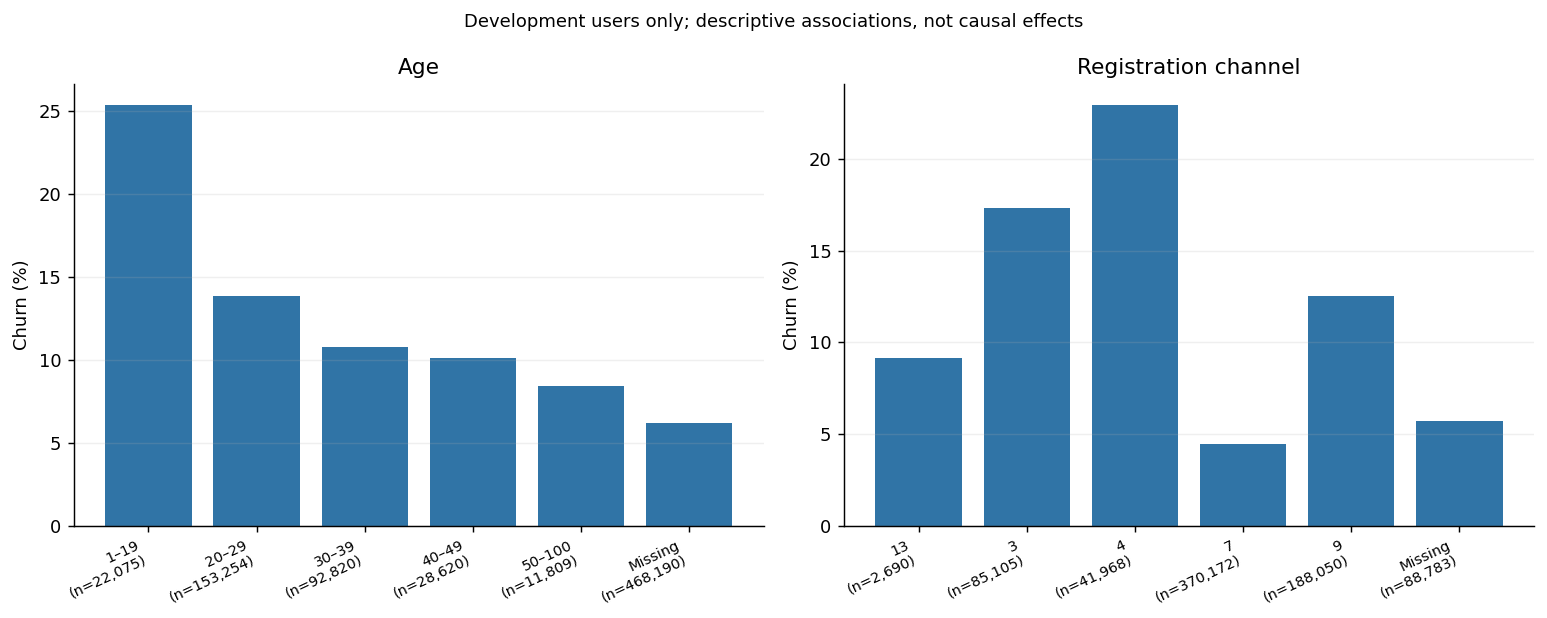

In [ ]:
filename, specs = chart_specs[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (expression, title) in zip(axes, specs):
    groups.append(rate_plot(con, ax, expression, title))
fig.suptitle('Development users only; descriptive associations, not causal effects', fontsize=10)
fig.tight_layout()
fig.savefig(OUTPUT / filename)
display(fig)
plt.close(fig)

## 12. Compact, interpretable feature specification

The following decisions preserve the existing recommendation, not an automatic feature-selection algorithm.
Use meaning, missingness, structural redundancy, and development-only evidence. The target and ID are kept
separately. Optional columns remain in the source Parquet but are excluded from the initial 24 predictors.
The three new attributes exist only in the development view; no reduced dataset or model is exported.

Historical listening intensity has implausible positive outliers; leave it optional pending raw-log auditing.
Gender is optional because it is mostly missing and observed male/female rates were nearly identical.
City and registration channel remain categorical. Missingness/history flags retain their distinct meanings.

In [ ]:
PREDICTORS = [
    "city", "age", "registered_via", "has_demographics",
    "membership_tenure_days", "has_listening_logs", "days_since_last_active",
    "active_days_7d", "active_days_30d", "listening_secs_30d",
    "listening_secs_change_30d", "song_completion_rate",
    "has_transactions", "transaction_count", "transaction_count_30d",
    "days_since_last_transaction", "last_amount_paid", "last_plan_days",
    "auto_renew_rate", "last_is_auto_renew", "cancel_count_90d", "last_is_cancel",
    "days_since_last_cancel", "days_until_expiration",
]

DECISIONS = {
    "msno": ("Remove", "Identifier and split/join key; never a predictor."),
    "is_churn": ("Remove", "Target, retained separately from predictors."),
    "city": ("Keep", "Location category; do not interpret numeric codes as ordered."),
    "age": ("Keep", "Interpretable demographic; retain NULL rather than invent an age."),
    "gender": ("Optional", "About 60% missing; observed male/female churn rates nearly identical in development."),
    "registered_via": ("Keep", "Acquisition channel category, not an ordered number."),
    "registration_date": ("Transform", "Replace raw date with membership_tenure_days."),
    "has_demographics": ("Keep", "Distinguishes usable demographics from absent/masked records."),
    "age_missing": ("Remove", "Exactly derivable from age NULL status."),
    "gender_missing": ("Remove", "Exactly derivable from gender NULL status."),
    "has_listening_logs": ("Keep", "Distinguishes missing history from observed zero activity."),
    "listening_record_count": ("Remove", "Row-count audit; use active dates for engagement."),
    "invalid_listening_rows": ("Remove", "Quality audit, not customer behavior; used to guard completion ratio."),
    "active_days": ("Optional", "Historical exposure; recent activity is easier to compare across users."),
    "total_songs": ("Transform", "Use as completion-rate denominator; omit raw historical volume."),
    "total_songs_100": ("Transform", "Use as completion-rate numerator; omit raw historical volume."),
    "total_unique_songs_daily": ("Remove", "Repeated daily counts, not distinct lifetime songs; another volume measure."),
    "total_listening_secs": ("Optional", "Historical volume/exposure; overlaps recent and average listening."),
    "avg_secs_per_active_day": ("Optional", "Implausible positive outliers contaminate historical intensity; omit until audited."),
    "last_active_date": ("Remove", "Exactly represented by days_since_last_active at fixed cutoff."),
    "days_since_last_active": ("Keep", "Interpretable inactivity/recency."),
    "active_days_7d": ("Keep", "Very recent activity; preserve alongside the longer window initially."),
    "active_days_30d": ("Keep", "Recent frequency distinct from listening intensity."),
    "listening_secs_7d": ("Optional", "Short-window volume; overlaps 30-day volume and 7-day frequency."),
    "listening_secs_30d": ("Keep", "Recent listening volume; skew/outliers require attention later."),
    "listening_secs_previous_30d": ("Remove", "Exactly recoverable from recent volume minus its change."),
    "songs_30d": ("Optional", "Alternative recent-volume measure to seconds."),
    "listening_secs_change_30d": ("Keep", "Absolute change between equal 30-day windows; negative is meaningful."),
    "listening_secs_ratio_30d": ("Remove", "Redundant with recent volume/change; undefined at zero prior activity."),
    "has_transactions": ("Keep", "Distinguishes no records from observed no recent transactions."),
    "transaction_count": ("Keep", "Observed history depth; counts events, not successful purchases."),
    "transaction_count_30d": ("Keep", "Recent transaction frequency."),
    "transaction_count_90d": ("Optional", "Intermediate window overlaps history and recent frequency."),
    "invalid_transaction_rows": ("Remove", "Data-quality audit; investigate invalid fields rather than modeling the count."),
    "last_transaction_date": ("Remove", "Exactly represented by days_since_last_transaction."),
    "days_since_last_transaction": ("Keep", "Payment/subscription interaction recency."),
    "total_amount_paid": ("Remove", "History-length driven and largely represented by frequency/payment size."),
    "avg_amount_paid": ("Optional", "Historical payment level; latest amount better reflects current plan."),
    "last_amount_paid": ("Keep", "Latest known payment, including legitimate zero-cost plans."),
    "avg_plan_days": ("Optional", "Historical duration; latest duration reflects current subscription."),
    "last_plan_days": ("Keep", "Current recorded plan duration."),
    "last_membership_expire_date": ("Transform", "Use signed days_until_expiration, masking the likely 1970-01-01 sentinel."),
    "auto_renew_rate": ("Keep", "Historical renewal preference."),
    "last_is_auto_renew": ("Keep", "Latest status may differ from historical preference."),
    "ever_cancel": ("Remove", "Derivable from observed cancel_count when flags are valid."),
    "cancel_count": ("Optional", "Historical cancellations; prefer recent 90-day count for comparability."),
    "cancel_ratio": ("Optional", "History-normalized cancellations; not equivalent to actual churn."),
    "last_is_cancel": ("Keep", "Latest recorded cancellation state; not the target itself."),
    "days_since_last_cancel": ("Keep", "Cancellation recency; NULL means no known cancellation or no history."),
    "cancel_count_30d": ("Optional", "Shorter version of retained 90-day cancellation count."),
    "cancel_count_90d": ("Keep", "Recent cancellation frequency."),
    "transactions_since_last_cancel": ("Optional", "Recovery signal overlaps cancellation/transaction recency."),
}

display(pd.DataFrame({'Predictor': PREDICTORS,
    'Origin': ['New derived' if c in derived else 'Existing Parquet' for c in PREDICTORS]}))
decisions = pd.DataFrame([(c, *DECISIONS[c]) for c in schema.column_name],
                         columns=['Original column', 'Decision', 'Reason'])
display(decisions)

,Predictor,Origin
0,city,Existing Parquet
1,age,Existing Parquet
2,registered_via,Existing Parquet
3,has_demographics,Existing Parquet
4,membership_tenure_days,New derived
5,has_listening_logs,Existing Parquet
6,days_since_last_active,Existing Parquet
7,active_days_7d,Existing Parquet
8,active_days_30d,Existing Parquet
9,listening_secs_30d,Existing Parquet


,Original column,Decision,Reason
0,msno,Remove,Identifier and split/join key; never a predictor.
1,is_churn,Remove,"Target, retained separately from predictors."
2,city,Keep,Location category; do not interpret numeric co...
3,age,Keep,Interpretable demographic; retain NULL rather ...
4,gender,Optional,About 60% missing; observed male/female churn ...
5,registered_via,Keep,"Acquisition channel category, not an ordered n..."
6,registration_date,Transform,Replace raw date with membership_tenure_days.
7,has_demographics,Keep,Distinguishes usable demographics from absent/...
8,age_missing,Remove,Exactly derivable from age NULL status.
9,gender_missing,Remove,Exactly derivable from gender NULL status.


### Correlations: find redundant numerical measures

Use a reproducible sample of up to 50,000 development users, not the held-out test set. Spearman correlation
compares ranks, making it suitable for skewed activity/count features. Require at least 500 complete pairs;
constant paired values are undefined. List absolute correlations >= 0.85. Correlation is evidence of overlap,
not an automatic removal rule and not target importance. The heatmap shows selected numerical predictors;
gray cells indicate undefined/insufficient pairs. Saved prior figure below; rerun to replace it.

In [ ]:
sample_ids = dev_ids.sample(n=min(50_000, len(dev_ids)), random_state=SEED)
con.register("sample_ids", sample_ids)
sample = con.execute('SELECT ' + ','.join(f'd."{c}"' for c in numeric + derived) +
                     ' FROM dev d INNER JOIN sample_ids USING (msno) ORDER BY msno').df()
correlations = sample.corr(method="spearman", min_periods=500)
pairs = []
for i, a in enumerate(correlations.columns):
    for b in correlations.columns[i+1:]:
        paired = sample[[a, b]].dropna()
        # Missingness indicators can become constant after pairwise deletion.
        if len(paired) < 500 or paired.nunique().min() < 2:
            correlations.loc[a, b] = correlations.loc[b, a] = np.nan
        elif abs(correlations.loc[a, b]) >= .85:
            pairs.append((a, b, correlations.loc[a, b], len(paired)))
pairs = pd.DataFrame(pairs, columns=["Feature A", "Feature B", "Spearman rho", "Pairwise n"])
if len(pairs):
    pairs = pairs.iloc[np.argsort(-pairs["Spearman rho"].abs().to_numpy())]

display(pairs.head(12))

,Feature A,Feature B,Spearman rho,Pairwise n
2,listening_record_count,active_days,1.000000,43802
15,total_songs_100,total_listening_secs,0.997492,43802
26,ever_cancel,cancel_count,0.995727,49865
28,cancel_count,cancel_ratio,0.992718,49865
27,ever_cancel,cancel_ratio,0.991094,49865
13,total_songs,total_listening_secs,0.991036,43802
23,listening_secs_30d,songs_30d,0.986248,43802
11,total_songs,total_songs_100,0.985935,43802
12,total_songs,total_unique_songs_daily,0.985843,43802
16,total_unique_songs_daily,total_listening_secs,0.975058,43802


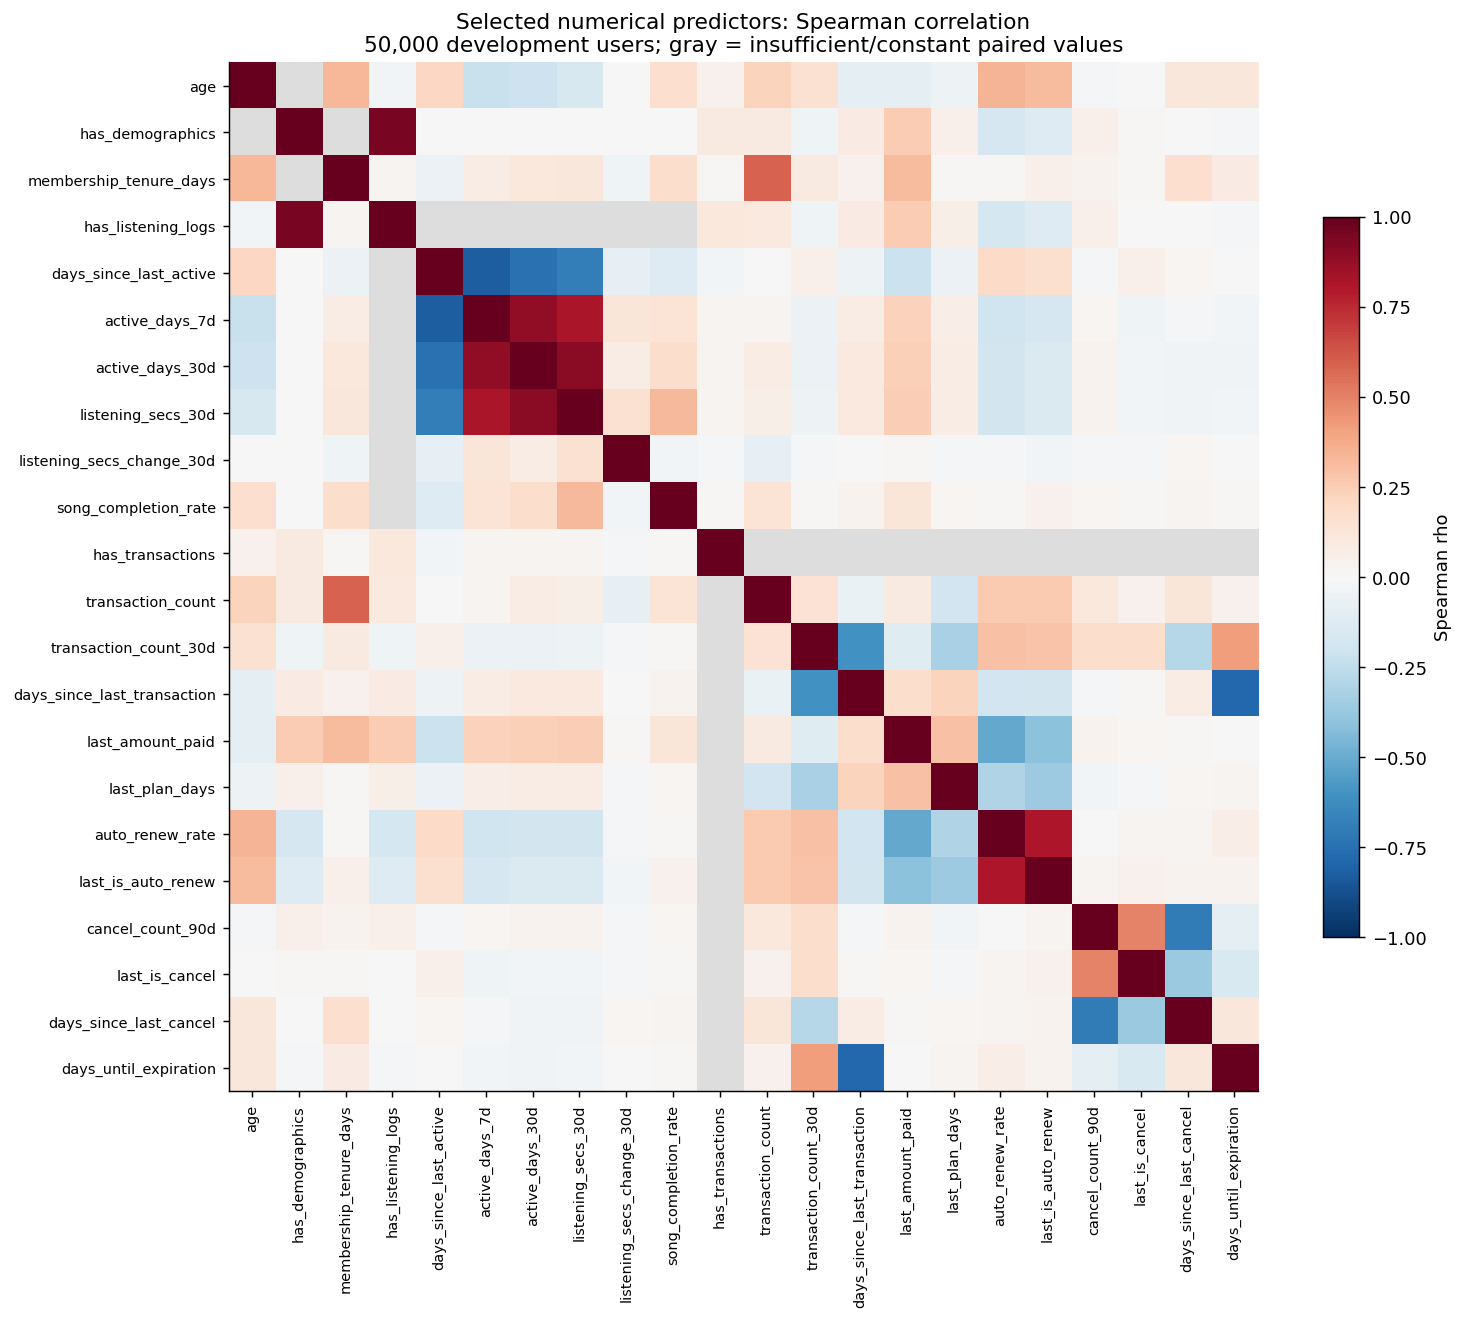

In [ ]:
heat_features = [c for c in PREDICTORS if c in correlations and sample[c].nunique() > 1]
matrix = correlations.loc[heat_features, heat_features]
fig, ax = plt.subplots(figsize=(12,10))
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#dddddd")
im = ax.imshow(np.ma.masked_invalid(matrix), vmin=-1, vmax=1, cmap=cmap)
ax.set_xticks(range(len(matrix)),matrix.columns,rotation=90,fontsize=8)
ax.set_yticks(range(len(matrix)),matrix.index,fontsize=8)
ax.set_title("Selected numerical predictors: Spearman correlation\n50,000 development users; gray = insufficient/constant paired values")
fig.colorbar(im, ax=ax, shrink=.7, label="Spearman rho")
fig.tight_layout(); fig.savefig(OUTPUT/'06_correlations.png'); display(fig); plt.close(fig)

### Supporting group summaries

Show city/gender comparisons, all plotted segment sizes/rates, and missingness in selected predictors.
These remain development-only, and group counts help judge how stable each percentage may be.

In [ ]:
categories = con.execute("""SELECT 'city' AS attribute, COALESCE(city,'Missing') AS value,
    COUNT(*) AS users, AVG(is_churn)*100 AS churn_pct FROM dev GROUP BY city
    UNION ALL SELECT 'gender', COALESCE(gender,'Missing'), COUNT(*), AVG(is_churn)*100
    FROM dev GROUP BY gender ORDER BY attribute, users DESC""").df()
group_table = pd.concat(groups, ignore_index=True)[["analysis", "segment", "users", "churn_pct"]]
group_table.segment = group_table.segment.str.replace(r"^\d+: ", "", regex=True)
decisions = pd.DataFrame([(c, *DECISIONS[c]) for c in schema.column_name],
                         columns=["Original column", "Decision", "Reason"])
display_quality = quality.drop(columns="Nonfinite").copy()
selected_missing = quality.set_index("Column").loc[PREDICTORS, "Missing %"].sort_values(ascending=False)


display(categories, group_table)
display(selected_missing.rename('Missing %').reset_index())

,attribute,value,users,churn_pct
0,city,1,353759,6.337365
1,city,Missing,88783,5.703795
2,city,13,77657,12.241009
3,city,5,56472,13.222482
4,city,4,37749,12.821532
5,city,15,34495,12.772866
6,city,22,33497,12.553363
7,city,6,20861,12.818177
8,city,14,15984,11.986987
9,city,12,9095,13.864761


,analysis,segment,users,churn_pct
0,Age,1–19,22075,25.354473
1,Age,20–29,153254,13.858692
2,Age,30–39,92820,10.787546
3,Age,40–49,28620,10.150245
4,Age,50–100,11809,8.459649
5,Age,Missing,468190,6.217775
6,Registration channel,13,2690,9.144981
7,Registration channel,3,85105,17.304506
8,Registration channel,4,41968,22.926992
9,Registration channel,7,370172,4.486563


,Column,Missing %
0,days_since_last_cancel,79.359603
1,age,60.274110
2,song_completion_rate,14.053875
3,active_days_7d,12.425203
4,active_days_30d,12.425203
5,listening_secs_30d,12.425203
6,days_since_last_active,12.425203
7,listening_secs_change_30d,12.425203
8,city,11.429796
9,membership_tenure_days,11.429796


These analyses use the existing development users only:

1. Auto-renewal × expiration timing.
2. Previous listening volume × change in listening.
3. Listening activity overall and within auto-renewal groups.

We compare listening seconds across two equal 30-day windows because previous-window active-day counts are not stored.

If the earlier cleanup cell closed DuckDB, the next cell restores only a lazy view of the same Parquet using the existing `dev_ids`. It does not download data, rerun preprocessing, or change the split.

In [ ]:
# Reuse the connection if it is open.
# The previous notebook's cleanup cell may have closed it.
try:
    con.execute("SELECT 1 FROM dev LIMIT 0").fetchall()
except duckdb.ConnectionException:
    con = duckdb.connect()
    con.execute("SET memory_limit='1GB'")
    con.execute("SET threads=1")

    parquet_path = globals().get("original_source", SOURCE)
    con.read_parquet(str(parquet_path)).create_view("source")
    con.register("dev_ids", dev_ids)

    con.execute("""
        CREATE VIEW dev AS
        SELECT s.*
        FROM source s
        INNER JOIN dev_ids USING (msno)
    """)

MIN_USERS = 100
interaction_output = OUTPUT / "interactions"
interaction_output.mkdir(parents=True, exist_ok=True)

con.execute("""
    CREATE OR REPLACE TEMP VIEW interaction_segments AS
    WITH segments AS (
        SELECT *,
            CASE
                WHEN last_is_auto_renew = 1 THEN 'Auto-renew on'
                WHEN last_is_auto_renew = 0 THEN 'Auto-renew off'
                ELSE 'Unknown'
            END AS renewal,

            CASE
                WHEN last_membership_expire_date IS NULL
                  OR last_membership_expire_date = DATE '1970-01-01'
                    THEN 'Unknown'
                WHEN last_membership_expire_date < DATE '2017-02-28'
                    THEN 'Expired'
                WHEN last_membership_expire_date = DATE '2017-02-28'
                    THEN 'Cutoff day'
                WHEN last_membership_expire_date <= DATE '2017-03-07'
                    THEN '1–7 days'
                WHEN last_membership_expire_date <= DATE '2017-03-30'
                    THEN '8–30 days'
                ELSE '>30 days'
            END AS expiration,

            CASE
                WHEN has_listening_logs = 0 THEN 'No history'
                WHEN invalid_listening_rows IS NULL
                  OR invalid_listening_rows > 0
                  OR listening_secs_30d IS NULL
                  OR listening_secs_previous_30d IS NULL
                  OR NOT ISFINITE(listening_secs_30d)
                  OR NOT ISFINITE(listening_secs_previous_30d)
                  OR listening_secs_30d < 0
                  OR listening_secs_previous_30d < 0
                  OR listening_secs_30d > 30 * 86400
                  OR listening_secs_previous_30d > 30 * 86400
                    THEN 'Unknown/flagged'
                ELSE 'Usable'
            END AS listening_quality
        FROM dev
    )
    SELECT *,
        CASE
            WHEN listening_quality <> 'Usable' THEN listening_quality
            WHEN listening_secs_previous_30d = 0 THEN '0 hours'
            WHEN listening_secs_previous_30d <= 5 * 3600 THEN '(0, 5] hours'
            WHEN listening_secs_previous_30d <= 20 * 3600 THEN '(5, 20] hours'
            WHEN listening_secs_previous_30d <= 60 * 3600 THEN '(20, 60] hours'
            ELSE '>60 hours'
        END AS previous_activity,

        CASE
            WHEN listening_quality <> 'Usable' THEN listening_quality
            WHEN listening_secs_previous_30d = 0
             AND listening_secs_30d = 0 THEN 'Inactive both'
            WHEN listening_secs_previous_30d = 0 THEN 'New/restarted'
            WHEN listening_secs_30d < 0.75 * listening_secs_previous_30d
                THEN 'Decline >25%'
            WHEN listening_secs_30d > 1.25 * listening_secs_previous_30d
                THEN 'Increase >25%'
            ELSE 'Stable ±25%'
        END AS listening_trend
    FROM segments
""")

###Auto-renewal × expiration timing

Does expiration timing relate to churn differently for automatic and manual renewal?

Each heatmap cell shows churn percentage and user count. Gray cells are empty or have fewer than 100 users (*).

Future expiration dates are allowed when recorded in pre-cutoff transactions. The likely `1970-01-01` placeholder is treated as unknown.

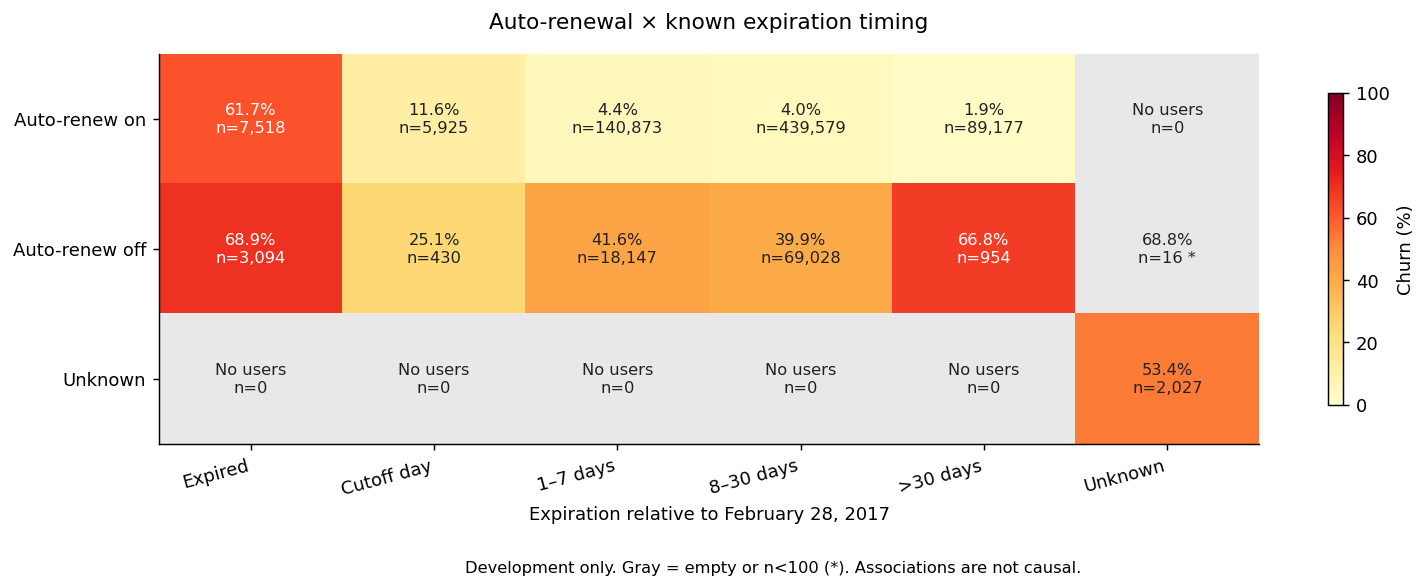

,renewal,expiration,users,churned,churn_pct
0,Auto-renew off,1–7 days,18147,7541,41.555078
1,Auto-renew off,8–30 days,69028,27573,39.944660
2,Auto-renew off,>30 days,954,637,66.771488
3,Auto-renew off,Cutoff day,430,108,25.116279
4,Auto-renew off,Expired,3094,2133,68.939884
5,Auto-renew off,Unknown,16,11,68.750000
6,Auto-renew on,1–7 days,140873,6164,4.375572
7,Auto-renew on,8–30 days,439579,17564,3.995641
8,Auto-renew on,>30 days,89177,1728,1.937719
9,Auto-renew on,Cutoff day,5925,686,11.578059


In [ ]:
def rate_heatmap(
    ax, table, row, column, row_order, column_order, title, upper=100
):
    rates = table.pivot(
        index=row, columns=column, values="churn_pct"
    ).reindex(index=row_order, columns=column_order)

    counts = table.pivot(
        index=row, columns=column, values="users"
    ).reindex(index=row_order, columns=column_order).fillna(0)

    cmap = plt.get_cmap("YlOrRd").copy()
    cmap.set_bad("#e8e8e8")

    colors = rates.where(counts >= MIN_USERS)
    image = ax.imshow(
        np.ma.masked_invalid(colors.to_numpy()),
        vmin=0, vmax=upper, cmap=cmap, aspect="auto"
    )

    for i in range(len(row_order)):
        for j in range(len(column_order)):
            n = int(counts.iloc[i, j])
            rate = rates.iloc[i, j]
            label = f"{rate:.1f}%\nn={n:,}" if n else "No users\nn=0"

            if 0 < n < MIN_USERS:
                label += " *"

            color = (
                "white"
                if n >= MIN_USERS and rate > upper * 0.6
                else "#222222"
            )
            ax.text(
                j, i, label, ha="center", va="center",
                fontsize=9, color=color
            )

    ax.set_xticks(
        range(len(column_order)), column_order,
        rotation=15, ha="right"
    )
    ax.set_yticks(range(len(row_order)), row_order)
    ax.set_title(title, pad=14)
    ax.figure.colorbar(image, ax=ax, label="Churn (%)", shrink=0.8)


expiration_groups = con.execute("""
    SELECT renewal, expiration,
           COUNT(*) AS users,
           SUM(is_churn) AS churned,
           AVG(is_churn) * 100 AS churn_pct
    FROM interaction_segments
    GROUP BY 1, 2
    ORDER BY 1, 2
""").df()

expiration_groups["churned"] = expiration_groups["churned"].astype("int64")

fig, ax = plt.subplots(figsize=(12, 4.5))

rate_heatmap(
    ax, expiration_groups, "renewal", "expiration",
    ["Auto-renew on", "Auto-renew off", "Unknown"],
    ["Expired", "Cutoff day", "1–7 days", "8–30 days", ">30 days", "Unknown"],
    "Auto-renewal × known expiration timing"
)

ax.set_xlabel("Expiration relative to February 28, 2017")
fig.text(
    0.5, 0.01,
    "Development only. Gray = empty or n<100 (*). Associations are not causal.",
    ha="center", fontsize=9
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(interaction_output / "07_auto_renew_expiration.png", dpi=140)
plt.show()
plt.close(fig)

expiration_groups.to_csv(
    interaction_output / "expiration_groups.csv", index=False
)
display(expiration_groups)

##Does renewal status mask the listening–churn relationship?

Plot churn against recorded listening days overall and within auto-renewal groups.

Shading shows pointwise 95% Wilson confidence intervals. Points with fewer than 100 users are omitted. No-history users are reported separately rather than treated as zero recent activity.

Panels use separate y-scales, each starting at zero. Overall includes unknown renewal status; the conditional panels do not.

Different patterns can indicate masking by group composition. They do not automatically establish Simpson’s paradox or causation.

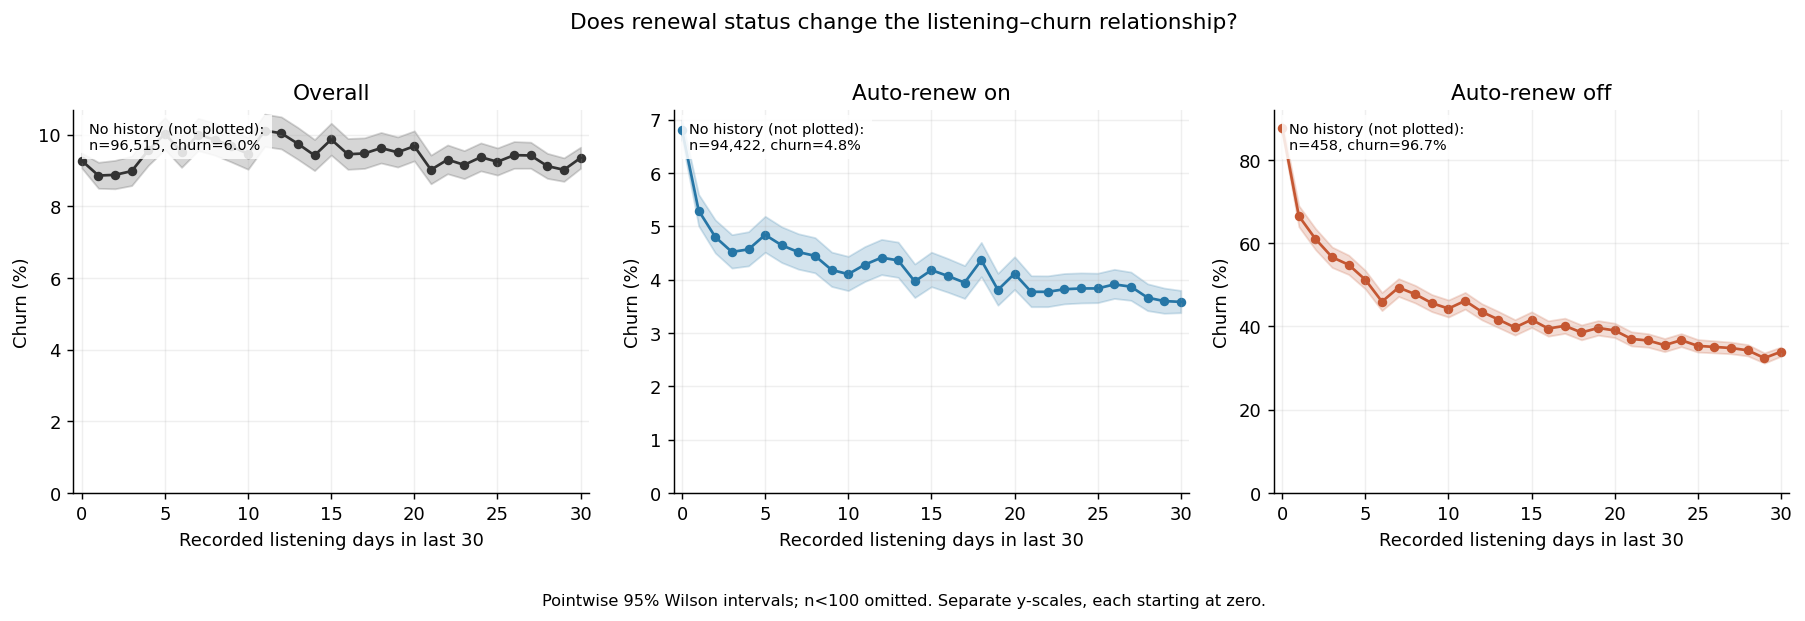

In [ ]:
curves = con.execute("""
    SELECT 'Overall' AS renewal, active_days_30d,
           COUNT(*) AS users,
           SUM(is_churn) AS churned,
           AVG(is_churn) * 100 AS churn_pct
    FROM interaction_segments
    GROUP BY 2

    UNION ALL

    SELECT renewal, active_days_30d,
           COUNT(*) AS users,
           SUM(is_churn) AS churned,
           AVG(is_churn) * 100 AS churn_pct
    FROM interaction_segments
    GROUP BY 1, 2
""").df()

curves["churned"] = curves["churned"].astype("int64")

# Pointwise 95% Wilson intervals for churn proportions.
z = 1.959963984540054
n = curves.users.to_numpy()
p = curves.churn_pct.to_numpy() / 100

center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
half = (
    z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    / (1 + z**2 / n)
)

curves["ci_low"] = np.maximum(0, center - half) * 100
curves["ci_high"] = np.minimum(1, center + half) * 100

fig, axes = plt.subplots(1, 3, figsize=(14, 4.7))

for ax, status, color in zip(
    axes,
    ["Overall", "Auto-renew on", "Auto-renew off"],
    ["#333333", "#2676a6", "#c55732"]
):
    data = curves[
        curves.renewal.eq(status) & curves.active_days_30d.notna()
    ].sort_values("active_days_30d")

    reliable = data.users >= MIN_USERS
    x = data.active_days_30d.to_numpy(dtype=float)

    ax.plot(x, data.churn_pct.where(reliable), color=color)
    ax.scatter(
        x[reliable], data.loc[reliable, "churn_pct"],
        color=color, s=18
    )
    ax.fill_between(
        x,
        data.ci_low.where(reliable).to_numpy(dtype=float),
        data.ci_high.where(reliable).to_numpy(dtype=float),
        color=color, alpha=0.2
    )

    ax.set(
        title=status,
        xlabel="Recorded listening days in last 30",
        ylabel="Churn (%)",
        xlim=(-0.5, 30.5)
    )
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)

    no_history = curves[
        curves.renewal.eq(status) & curves.active_days_30d.isna()
    ]
    if len(no_history):
        row = no_history.iloc[0]
        ax.text(
            0.03, 0.97,
            f"No history (not plotted):\n"
            f"n={int(row.users):,}, churn={row.churn_pct:.1f}%",
            transform=ax.transAxes, va="top", fontsize=8,
            bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"}
        )

fig.suptitle(
    "Does renewal status change the listening–churn relationship?"
)
fig.text(
    0.5, 0.01,
    "Pointwise 95% Wilson intervals; n<100 omitted. Separate y-scales, each starting at zero.",
    ha="center", fontsize=9
)
fig.tight_layout(rect=(0, 0.07, 1, 0.96))
fig.savefig(interaction_output / "09_listening_by_auto_renew.png", dpi=140)
plt.show()
plt.close(fig)

curves.to_csv(interaction_output / "curves_groups.csv", index=False)

## 13. Interpretation, reproducibility limits, and cleanup

- Supplied churn labels are unchanged. Their exact generation/horizon has not been independently reproduced;
  published month descriptions are inconsistent. Our explicit observation cutoff is February 28, 2017.
- The member table is a later unversioned snapshot. Masking future registrations cannot certify historical
  availability of every remaining demographic value.
- Recorded activity is not necessarily positive activity. Sums with invalid measurements can be partial totals.
  Large finite positive outliers survive preprocessing; the EDA diagnoses them, not silently repairs them.
- Recent listening was not a simple separator in the previous results; subscription state showed larger
  descriptive differences. Retained predictors are candidates, not proven useful features.
- A v1-to-v2 experiment would need label-maturity and repeated-user qualifications. The current holdout is
  within one cohort. Future encoders, imputers, clipping rules, and model selection must use training folds only.
- Output includes the final Parquet/metadata (raw route), six figures, and saved test IDs. The same seed and
  sorted IDs preserve the earlier development/test boundary. Numerical floating totals may differ in their
  last bits across execution environments/order; the feature definitions remain identical.

The cell below checks the supplied Parquet's size/mtime were unchanged during EDA, closes DuckDB, and releases
scratch storage. It performs no modeling. Save the executed notebook and needed output files to persistent
storage. If an earlier cell fails, this cleanup cell can also release this notebook's scratch directories.

References: [KKBox competition](https://www.kaggle.com/competitions/kkbox-churn-prediction-challenge),
[organizer paper](https://sdlinpaper.csie.ntu.edu.tw/publications/Conference/Music%20Recommendation%20and%20Churn%20Prediction..pdf),
[Colab storage/runtime guidance](https://research.google.com/colaboratory/faq.html).

In [ ]:
if 'con' in globals():
    con.close()
for session_name in ['listening_session', 'work_session', 'local_input']:
    session = globals().get(session_name)
    if session is not None:
        session.cleanup()
if 'original_source' in globals():
    if (original_source.stat().st_size, original_source.stat().st_mtime_ns) != original_stat:
        raise RuntimeError('The supplied Parquet changed during analysis.')
print('Complete: preprocessing/EDA only. No models trained and no test performance evaluated.')

Complete: preprocessing/EDA only. No models trained and no test performance evaluated.
